# 1. Dataset exploration:

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# pytorch has many built-in datasets
data_path = "./data"
train_dataset = torchvision.datasets.CIFAR10(
    root = data_path,
    download = True,
    train = True
)

Files already downloaded and verified


In [3]:
test_dataset = torchvision.datasets.CIFAR10(
    root=data_path,
    download=True,
    train=False
)

Files already downloaded and verified


In [353]:
print("number of pictures in the train dataset : ", len(train_dataset))
print("number of pictures in the test dataset : ", len(test_dataset))
image, lable = train_dataset[1]
print("each picture's informations : ", image)
print("each picture's size : ", image.size)
print("classes: ", train_dataset.classes)
print("number of classes: ", len(train_dataset.classes))

number of pictures in the train dataset :  50000
number of pictures in the test dataset :  10000
each picture's informations :  <PIL.Image.Image image mode=RGB size=32x32 at 0x2191CC97880>
each picture's size :  (32, 32)
classes:  ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
number of classes:  10


In [354]:
from collections import Counter
train_counter = Counter(train_dataset.targets)
test_counter = Counter(test_dataset.targets)
print("train dataset : ", train_counter)
print("test dataset : ", test_counter)

train dataset :  Counter({6: 5000, 9: 5000, 4: 5000, 1: 5000, 2: 5000, 7: 5000, 8: 5000, 3: 5000, 5: 5000, 0: 5000})
test dataset :  Counter({3: 1000, 8: 1000, 0: 1000, 6: 1000, 1: 1000, 9: 1000, 5: 1000, 7: 1000, 4: 1000, 2: 1000})


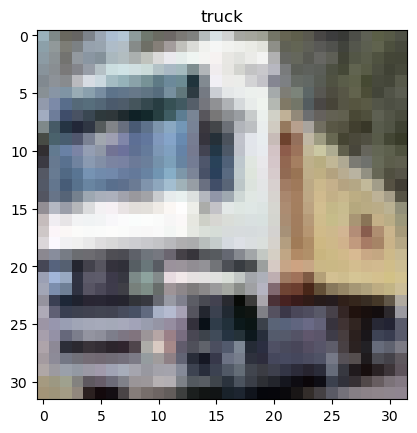

In [355]:
image, lable = train_dataset[1]
plt.imshow(image)
plt.title(train_dataset.classes[lable])
plt.show()

# 2. Visualization of samples:

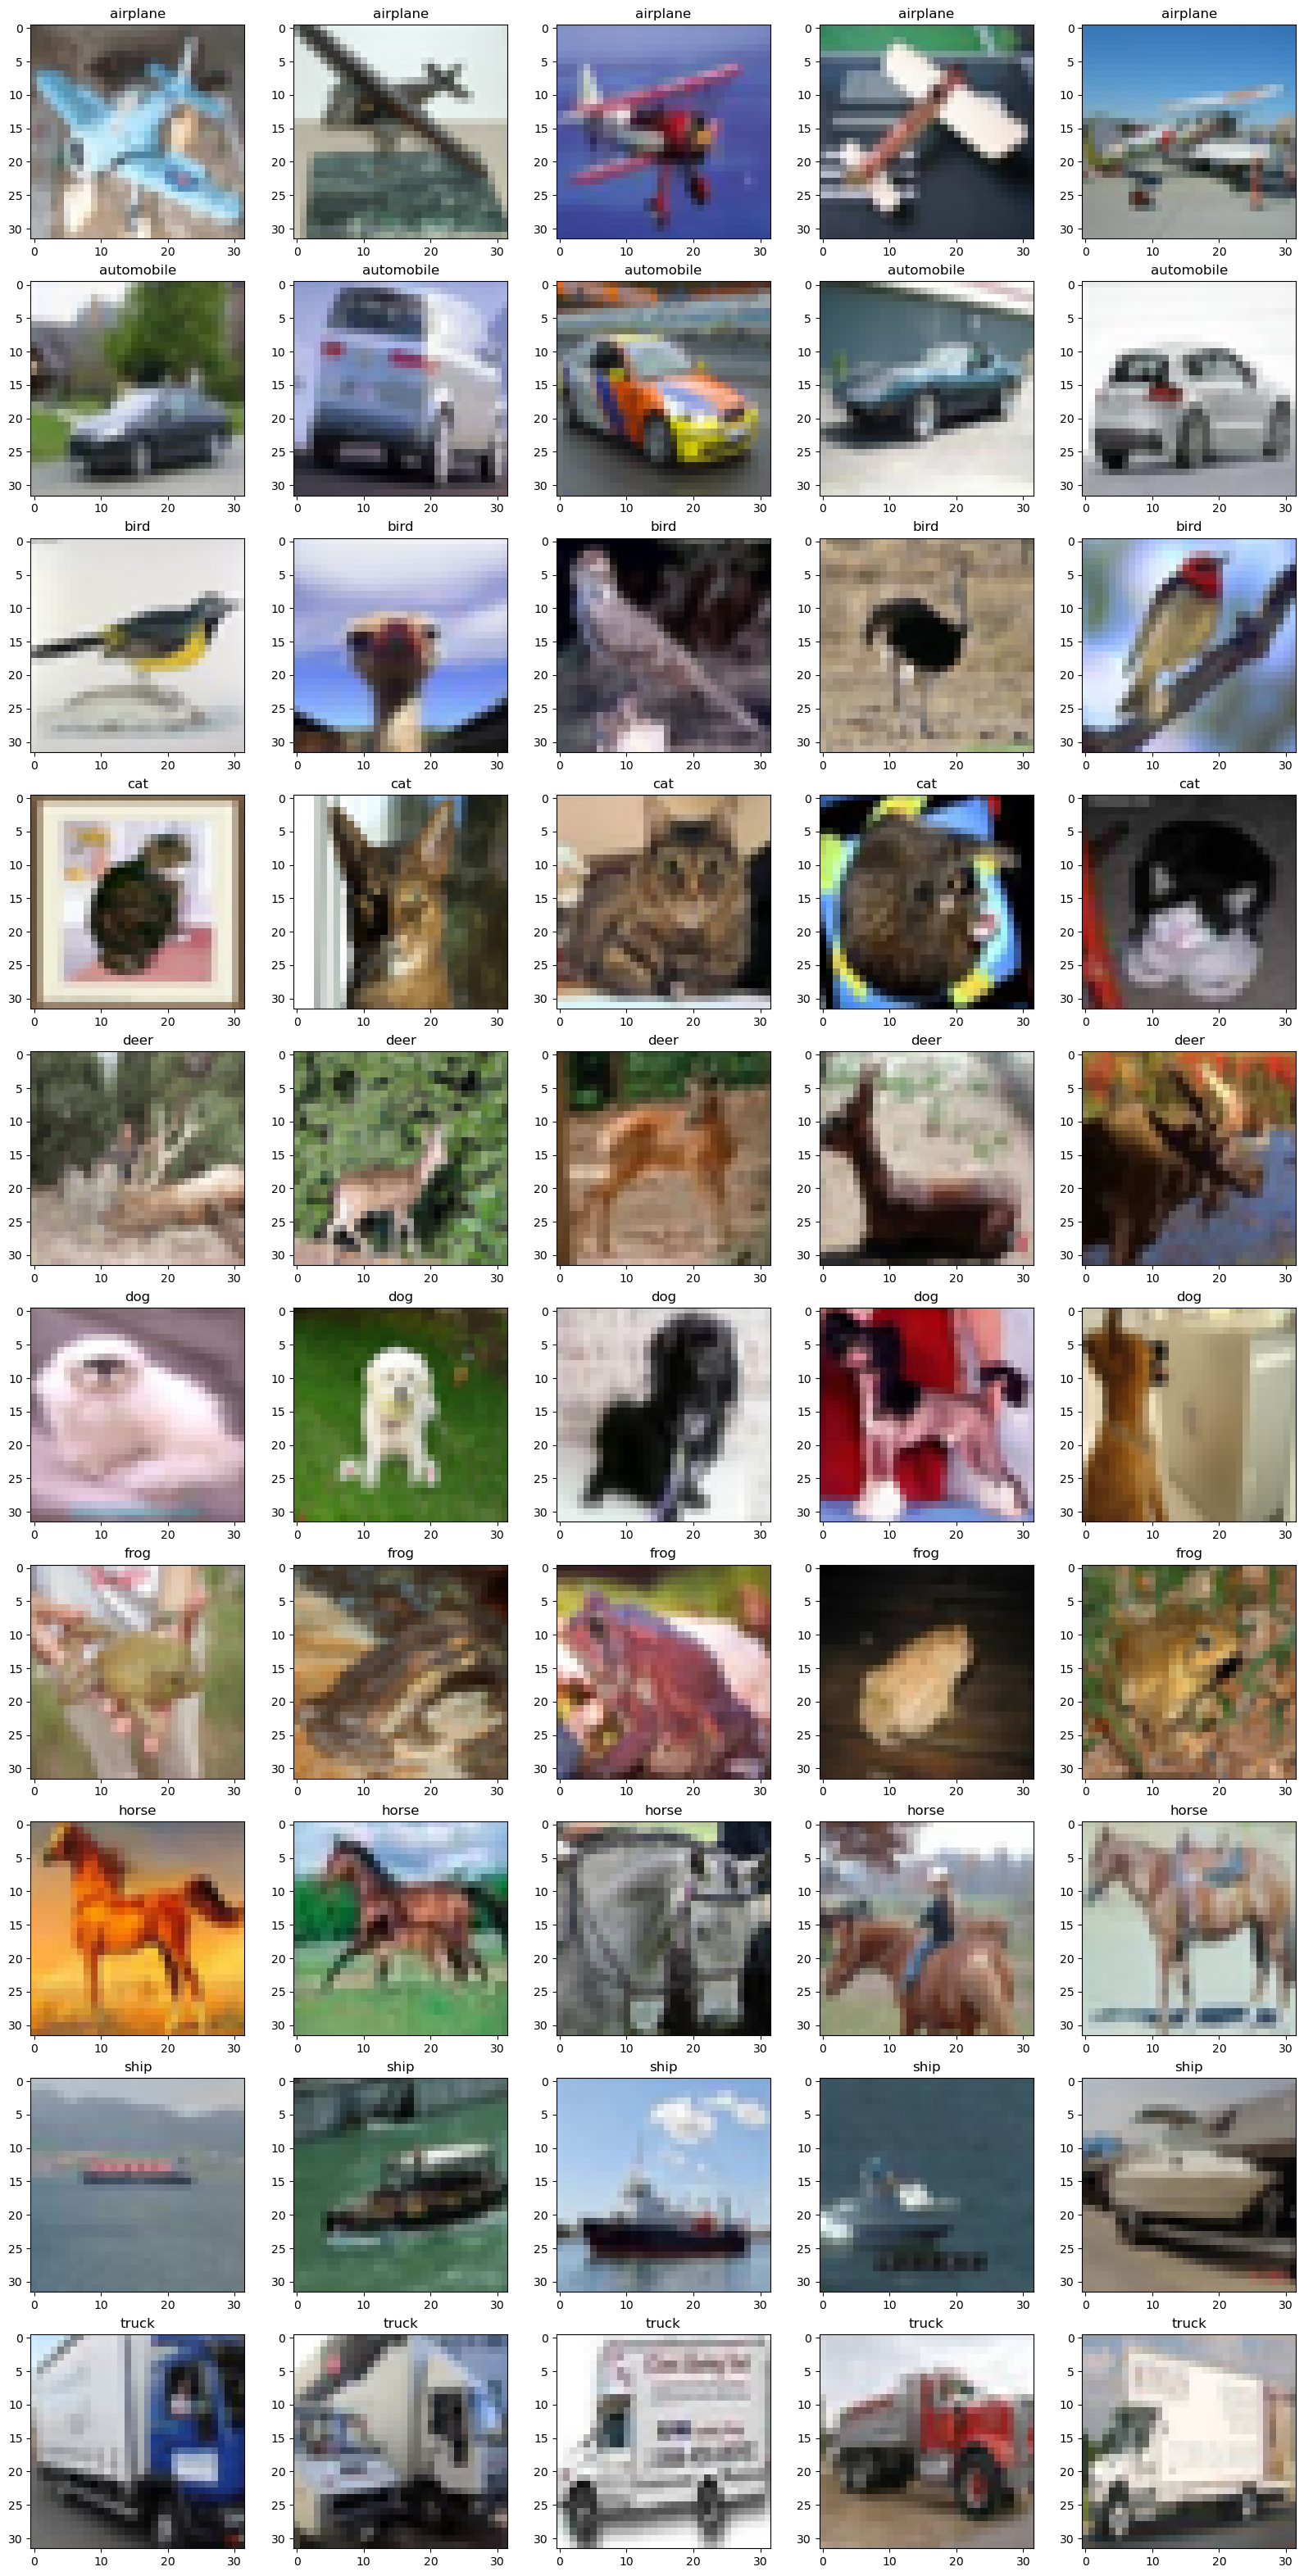

In [356]:
classes = test_dataset.classes
class_indices = [[] for i in range(len(classes))]
for i in range(len(test_dataset)):
    _, lable = test_dataset[i]
    class_indices[lable].append(i)

plt.figure(figsize=(20, 40))
for i in range(len(classes)):
    for j in range(5):
        image_idx = class_indices[i][torch.randint(0, 1000, (1, 1)).item()]
        image, lable = test_dataset[image_idx]
        plt.subplot(len(classes), 5, i * 5 + j + 1)
        plt.imshow(image)
        plt.title(classes[lable])
plt.show()

# 3. Building Fully Connected Layers (Manual Implementation):

In [3]:
# pytorch has many built-in datasets
data_path = "./data"
train_dataset = torchvision.datasets.CIFAR10(
    root = data_path,
    download = True,
    train = True,
    transform=transforms.ToTensor()
)

Files already downloaded and verified


In [4]:
test_dataset = torchvision.datasets.CIFAR10(
    root=data_path,
    download=True,
    train=False,
    transform=transforms.ToTensor()
)

Files already downloaded and verified


In [5]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

In [6]:
class SimpleMNISTNN(nn.Module):

    def __init__(self):
        super(SimpleMNISTNN, self).__init__()
        self.flatten = nn.Flatten()
        self.layers = nn.Sequential(
            nn.Linear(3072, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        x = self.layers(x)
        return x

# 4. Model Training (Using Manual Layers) :

In [7]:
model = SimpleMNISTNN()
optimizer = optim.Adam(model.parameters(), lr = 0.001)
loss_function = nn.CrossEntropyLoss()

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [9]:
def train_epoch(model, optimizer, loss_function, train_loader, device):

    model = model.to(device)
    model.train()
    epoch_loss = 0.0

    num_correct_predictions = 0
    total_predictions = 0
    total_batches = len(train_loader) # number of batches

    for batch_idx, (inputs, targets) in enumerate(train_loader): # explanation 1
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = loss_function(outputs, targets)
        loss.backward()
        optimizer.step()

        loss_value = loss.item()
        epoch_loss += loss_value

        _, predicted_indices = outputs.max(1) # explanation 2
        batch_size = targets.size(0) # explanation 3
        total_predictions += batch_size
        num_correct_in_batch = predicted_indices.eq(targets).sum().item() # explanation 4
        num_correct_predictions += num_correct_in_batch
    
    avg_epoch_loss = epoch_loss / total_batches
    accuracy = num_correct_predictions / total_predictions * 100

    print(f'\tLoss: {avg_epoch_loss:.3f} | Acc: {accuracy:.2f}%')
    return model, avg_epoch_loss, accuracy

In [10]:
def evaluate(model, test_loader, device):
    model.eval()
    loss_value = 0.0
    total_batches = len(test_loader)
    num_correct_predictions = 0
    total_predictions = 0

    with torch.no_grad():
        for inputs, targets in test_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = loss_function(outputs, targets)
            loss_value += loss.item()
            _, precited_indices = outputs.max(1)
            batch_size = targets.size(0)
            total_predictions += batch_size
            num_correct_in_batch = precited_indices.eq(targets).sum().item()
            num_correct_predictions += num_correct_in_batch

    accuracy = num_correct_predictions / total_predictions * 100
    avg_running_loss = loss_value / total_batches
    print(f'\tLoss: {avg_running_loss:.3f} | Acc: {accuracy:.2f}%')
    return accuracy, avg_running_loss

In [11]:
num_epoch = 10
train_loss = []
test_loss = []
train_acc = []
test_acc = []

for epoch in range(num_epoch):
    print(f'\n[Training] Epoch {epoch+1}:')
    train_model, train_loss_value, train_acc_value = train_epoch(model, optimizer, loss_function, train_loader, device)
    train_loss.append(train_loss_value)
    train_acc.append(train_acc_value)
    
    print(f'[Testing] Epoch {epoch+1}:')
    test_accuracy_value, test_loss_value = evaluate(train_model, test_loader, device)
    test_acc.append(test_accuracy_value)
    test_loss.append(test_loss_value) 


[Training] Epoch 1:
	Loss: 1.874 | Acc: 31.18%
[Testing] Epoch 1:
	Loss: 1.747 | Acc: 35.71%

[Training] Epoch 2:
	Loss: 1.699 | Acc: 38.59%
[Testing] Epoch 2:
	Loss: 1.627 | Acc: 41.96%

[Training] Epoch 3:
	Loss: 1.608 | Acc: 42.28%
[Testing] Epoch 3:
	Loss: 1.568 | Acc: 43.43%

[Training] Epoch 4:
	Loss: 1.537 | Acc: 44.70%
[Testing] Epoch 4:
	Loss: 1.504 | Acc: 45.98%

[Training] Epoch 5:
	Loss: 1.490 | Acc: 46.39%
[Testing] Epoch 5:
	Loss: 1.510 | Acc: 46.20%

[Training] Epoch 6:
	Loss: 1.447 | Acc: 48.03%
[Testing] Epoch 6:
	Loss: 1.482 | Acc: 47.51%

[Training] Epoch 7:
	Loss: 1.413 | Acc: 49.25%
[Testing] Epoch 7:
	Loss: 1.488 | Acc: 46.72%

[Training] Epoch 8:
	Loss: 1.383 | Acc: 50.33%
[Testing] Epoch 8:
	Loss: 1.443 | Acc: 49.18%

[Training] Epoch 9:
	Loss: 1.355 | Acc: 51.10%
[Testing] Epoch 9:
	Loss: 1.438 | Acc: 48.47%

[Training] Epoch 10:
	Loss: 1.328 | Acc: 52.19%
[Testing] Epoch 10:
	Loss: 1.454 | Acc: 48.79%


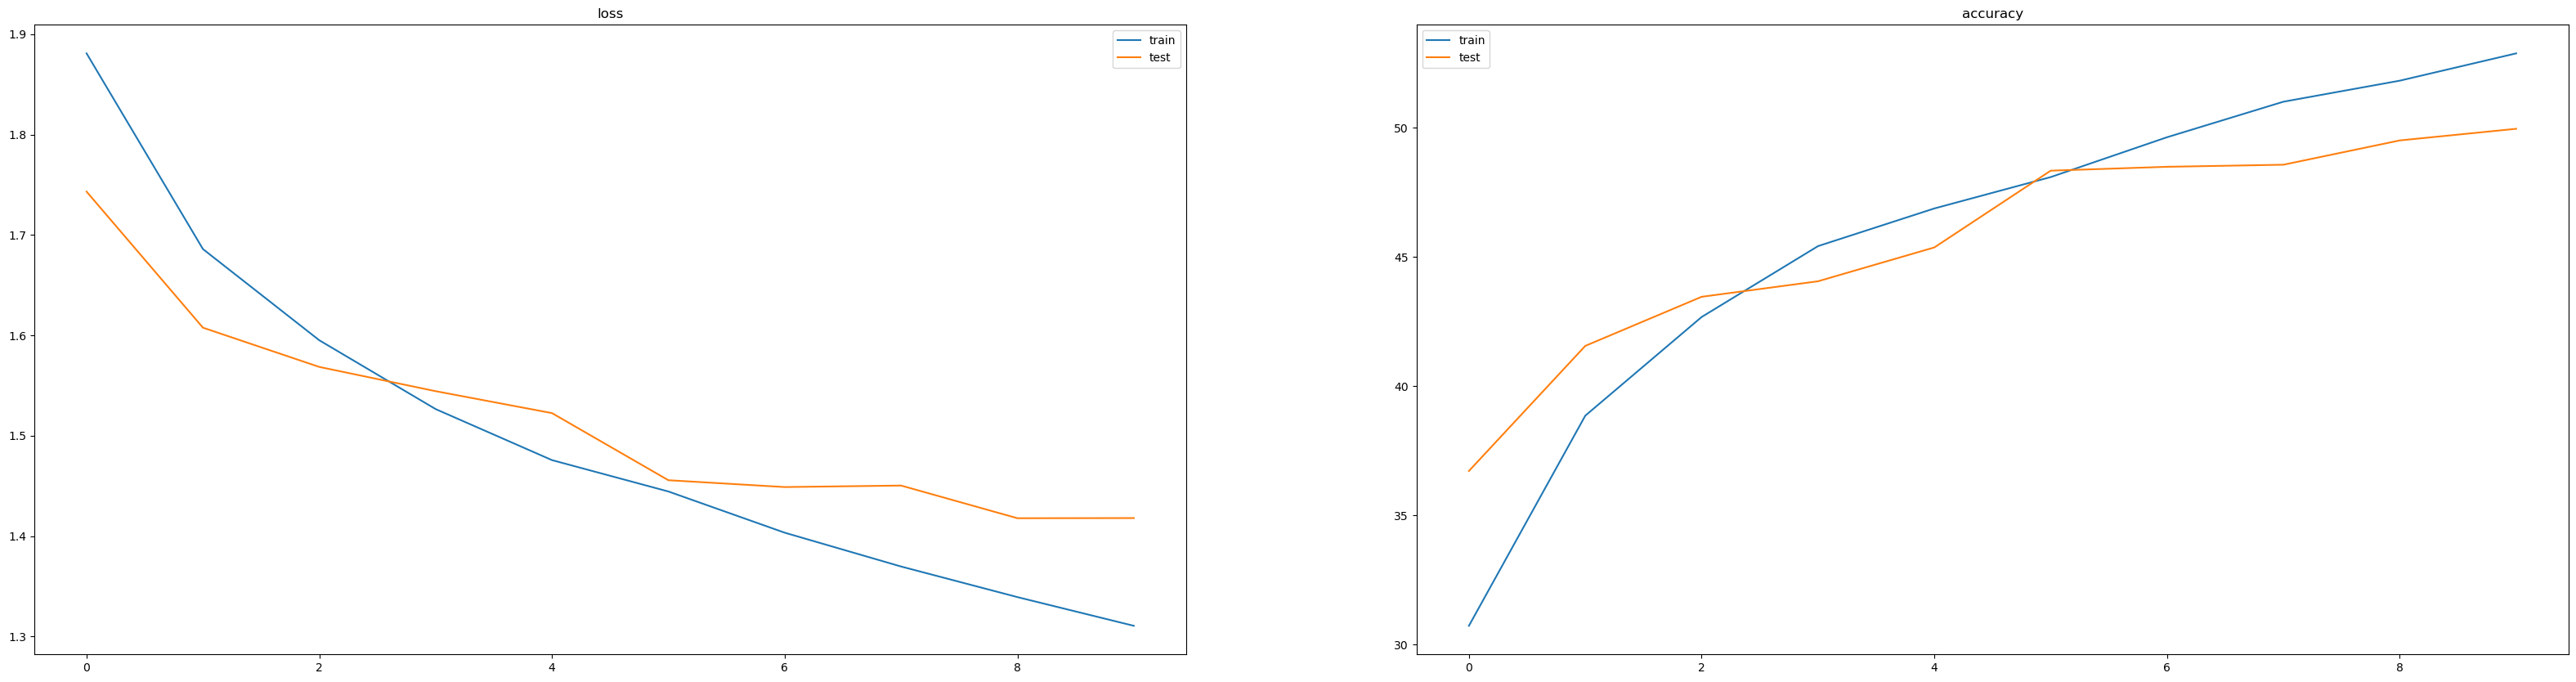

In [371]:
plt.figure(figsize=(40, 10))
plt.subplot(1, 2, 1)
plt.plot(range(10), train_loss, label="train")
plt.plot(range(10), test_loss, label="test")
plt.title("loss")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(range(10), train_acc, label="train")
plt.plot(range(10), test_acc, label="test")
plt.title("accuracy")
plt.legend()
plt.show()

# 7. Model Evaluation

In [372]:
num_classes = len(classes)

correct = np.zeros(num_classes)
total = np.zeros(num_classes)
cm = torch.zeros(num_classes, num_classes)

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)

        #confusion matrix
        for t, p in zip(labels, predicted):
            cm[t, p] += 1

        # update per-class counts
        for i in range(len(labels)):
            label = labels[i].item()
            total[label] += 1
            if predicted[i].item() == label:
                correct[label] += 1

# compute accuracy
per_class_accuracy = correct / total

for i in range(num_classes):
    print(f"{classes[i]} : {per_class_accuracy[i] * 100:.2f}%")

print(cm)

airplane : 57.50%
automobile : 61.90%
bird : 35.20%
cat : 29.30%
deer : 46.80%
dog : 37.90%
frog : 50.60%
horse : 60.50%
ship : 66.80%
truck : 53.10%
tensor([[575.,  33.,  43.,  20.,  43.,   9.,  13.,  37., 187.,  40.],
        [ 49., 619.,  22.,  12.,  16.,  18.,  10.,  34.,  71., 149.],
        [ 95.,  24., 352.,  70., 166.,  65.,  89.,  84.,  33.,  22.],
        [ 50.,  23.,  88., 293.,  87., 187.,  81.,  79.,  45.,  67.],
        [ 63.,  17., 124.,  44., 468.,  42., 106.,  91.,  34.,  11.],
        [ 31.,  19.,  74., 168.,  73., 379.,  73., 107.,  42.,  34.],
        [ 28.,  24.,  85.,  68., 136.,  52., 506.,  47.,  27.,  27.],
        [ 56.,  24.,  48.,  31., 105.,  49.,  17., 605.,  18.,  47.],
        [106.,  90.,  12.,  15.,  27.,  11.,   6.,  14., 668.,  51.],
        [ 54., 197.,  12.,  16.,  15.,  15.,  11.,  55.,  94., 531.]])


# 8. Discussion:

In [349]:
num_epoch = 10
from sklearn.neighbors import KNeighborsClassifier

def dataset_to_numpy(dataset):
    X = np.stack([np.array(dataset[i][0]).reshape(-1) for i in range(len(dataset))])
    y = np.array([dataset[i][1] for i in range(len(dataset))])
    return X, y

X_train, y_train = dataset_to_numpy(train_dataset)
X_test,  y_test  = dataset_to_numpy(test_dataset)

knn = KNeighborsClassifier(n_neighbors=3, metric='euclidean')
knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)
accuracy = (y_pred == y_test).mean() * 100
print(f"KNN accuracy: {accuracy:.2f}")

KNN accuracy: 33.03


# 6. Overfitting Demonstration

In [26]:
from torch.utils.data import Subset
small_dataset = Subset(train_dataset, list(range(500)))
small_train_loader = DataLoader(small_dataset, batch_size=64, shuffle=True)

In [33]:
model = SimpleMNISTNN()
optimizer = optim.Adam(model.parameters(), lr = 0.001)
num_epoch = 100
train_acc = []
test_acc = []

for epoch in range(num_epoch):
    print(f'\n[Training] Epoch {epoch+1}:')
    train_model, train_loss_value, train_acc_value = train_epoch(model, optimizer, loss_function, small_train_loader, device)
    train_acc.append(train_acc_value)
    
    print(f'[Testing] Epoch {epoch+1}:')
    test_accuracy_value, test_loss_value = evaluate(train_model, test_loader, device)
    test_acc.append(test_accuracy_value)


[Training] Epoch 1:
	Loss: 2.315 | Acc: 9.00%
[Testing] Epoch 1:
	Loss: 2.282 | Acc: 11.08%

[Training] Epoch 2:
	Loss: 2.232 | Acc: 16.20%
[Testing] Epoch 2:
	Loss: 2.203 | Acc: 17.51%

[Training] Epoch 3:
	Loss: 2.140 | Acc: 18.80%
[Testing] Epoch 3:
	Loss: 2.200 | Acc: 17.08%

[Training] Epoch 4:
	Loss: 2.098 | Acc: 24.00%
[Testing] Epoch 4:
	Loss: 2.076 | Acc: 22.95%

[Training] Epoch 5:
	Loss: 1.992 | Acc: 27.80%
[Testing] Epoch 5:
	Loss: 2.045 | Acc: 24.01%

[Training] Epoch 6:
	Loss: 1.923 | Acc: 28.80%
[Testing] Epoch 6:
	Loss: 2.024 | Acc: 26.53%

[Training] Epoch 7:
	Loss: 1.873 | Acc: 29.20%
[Testing] Epoch 7:
	Loss: 2.080 | Acc: 23.74%

[Training] Epoch 8:
	Loss: 1.848 | Acc: 30.60%
[Testing] Epoch 8:
	Loss: 2.030 | Acc: 24.91%

[Training] Epoch 9:
	Loss: 1.823 | Acc: 33.00%
[Testing] Epoch 9:
	Loss: 1.996 | Acc: 27.47%

[Training] Epoch 10:
	Loss: 1.790 | Acc: 32.80%
[Testing] Epoch 10:
	Loss: 1.990 | Acc: 26.98%

[Training] Epoch 11:
	Loss: 1.732 | Acc: 35.20%
[Testing] 

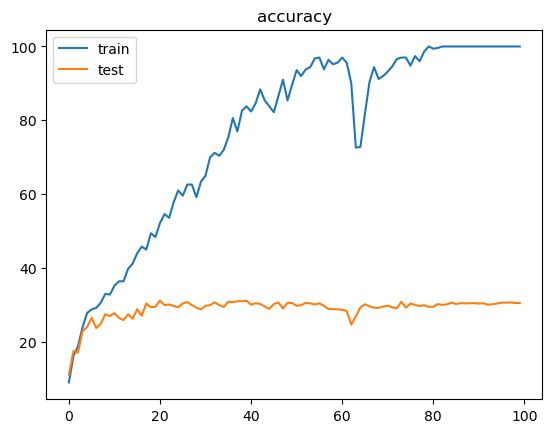

In [34]:
plt.plot(range(100), train_acc, label="train")
plt.plot(range(100), test_acc, label="test")
plt.title("accuracy")
plt.legend()
plt.show()

In [37]:
num_epoch = 100
train_acc = []
test_acc = []
model = SimpleMNISTNN()
optimizer = optim.Adam(model.parameters(), lr = 0.001, weight_decay=0.1)

for epoch in range(num_epoch):
    print(f'\n[Training] Epoch {epoch+1}:')
    train_model, train_loss_value, train_acc_value = train_epoch(model, optimizer, loss_function, small_train_loader, device)
    train_acc.append(train_acc_value)
    
    print(f'[Testing] Epoch {epoch+1}:')
    test_accuracy_value, test_loss_value = evaluate(train_model, test_loader, device)
    test_acc.append(test_accuracy_value)


[Training] Epoch 1:
	Loss: 2.299 | Acc: 11.40%
[Testing] Epoch 1:
	Loss: 2.298 | Acc: 11.84%

[Training] Epoch 2:
	Loss: 2.293 | Acc: 14.20%
[Testing] Epoch 2:
	Loss: 2.299 | Acc: 10.02%

[Training] Epoch 3:
	Loss: 2.292 | Acc: 10.60%
[Testing] Epoch 3:
	Loss: 2.299 | Acc: 10.04%

[Training] Epoch 4:
	Loss: 2.295 | Acc: 10.60%
[Testing] Epoch 4:
	Loss: 2.300 | Acc: 8.09%

[Training] Epoch 5:
	Loss: 2.295 | Acc: 10.40%
[Testing] Epoch 5:
	Loss: 2.301 | Acc: 10.03%

[Training] Epoch 6:
	Loss: 2.298 | Acc: 13.40%
[Testing] Epoch 6:
	Loss: 2.302 | Acc: 10.07%

[Training] Epoch 7:
	Loss: 2.299 | Acc: 13.00%
[Testing] Epoch 7:
	Loss: 2.303 | Acc: 10.00%

[Training] Epoch 8:
	Loss: 2.300 | Acc: 13.00%
[Testing] Epoch 8:
	Loss: 2.303 | Acc: 10.00%

[Training] Epoch 9:
	Loss: 2.300 | Acc: 13.00%
[Testing] Epoch 9:
	Loss: 2.303 | Acc: 10.00%

[Training] Epoch 10:
	Loss: 2.300 | Acc: 13.00%
[Testing] Epoch 10:
	Loss: 2.303 | Acc: 10.00%

[Training] Epoch 11:
	Loss: 2.300 | Acc: 13.00%
[Testing] 

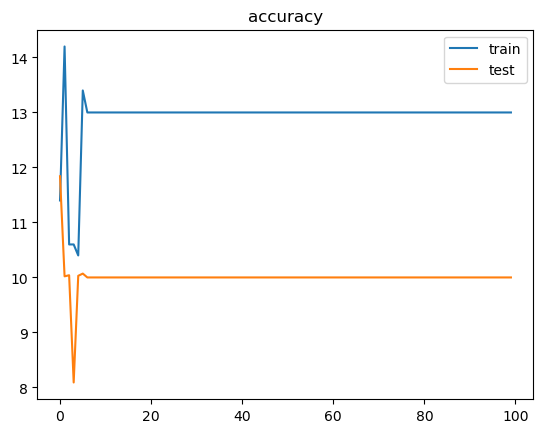

In [38]:
plt.plot(range(100), train_acc, label="train")
plt.plot(range(100), test_acc, label="test")
plt.title("accuracy")
plt.legend()
plt.show()